# Classification — Implementation Cheatsheet

Theory: [classification.md](classification.md) · Metrics: [evaluation_metrics.md](../01_toolkit/evaluation_metrics.md#2-classification-predicting-a-class)

**Dataset:** ExtraaLearn: 4,612 leads of an online education company. **Target:** `status` (1 = lead converted to a paid customer).
**Business goal:** find as many future customers as possible, so we optimize **recall** (missing a real customer = lost revenue).

| # | Section |
|---|---|
| 1 | Setup & data |
| 2 | Cleaning |
| 3 | Quick EDA |
| 4 | Encoding & stratified split |
| 5 | Evaluation helper |
| 6 | Logistic Regression (+ odds ratios, threshold tuning) |
| 7 | KNN & SVM (distance-based, need scaling) |
| 8 | Decision Tree (overfit → tuned) |
| 9 | Ensembles: Random Forest, AdaBoost, Gradient Boosting |
| 10 | Model comparison (+ ROC curves) |
| 11 | Feature importance & conclusion |

## 1. Setup & data

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             classification_report, ConfusionMatrixDisplay, RocCurveDisplay,
                             precision_recall_curve)

pd.set_option("display.max_columns", None)
SEED = 1
TARGET = "status"

In [2]:
data = pd.read_csv("../data/extraalearn.csv")
print(data.shape)
data.head()

(4612, 15)


,ID,age,current_occupation,first_interaction,profile_completed,website_visits,time_spent_on_website,page_views_per_visit,last_activity,print_media_type1,print_media_type2,digital_media,educational_channels,referral,status
0,EXT001,57,Unemployed,Website,High,7,1639,1.861,Website Activity,Yes,No,Yes,No,No,1
1,EXT002,56,Professional,Mobile App,Medium,2,83,0.320,Website Activity,No,No,No,Yes,No,0
2,EXT003,52,Professional,Website,Medium,3,330,0.074,Website Activity,No,No,Yes,No,No,0
3,EXT004,53,Unemployed,Website,High,4,464,2.057,Website Activity,No,No,No,No,No,1
4,EXT005,23,Student,Website,High,4,600,16.914,Email Activity,No,No,No,No,No,0


## 2. Cleaning

In [3]:
df = data.drop(columns="ID")          # unique per row: no information

# Duplicates only show up after dropping the ID
print("duplicates:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)

# Yes/No columns -> 1/0
yes_no = ["print_media_type1", "print_media_type2", "digital_media", "educational_channels", "referral"]
df[yes_no] = (df[yes_no] == "Yes").astype(int)

print(df.shape, "| missing:", df.isna().sum().sum())
df[TARGET].value_counts(normalize=True).round(3)

duplicates: 14
(4598, 14) | missing: 0


status
0    0.701
1    0.299
Name: proportion, dtype: float64

**~30% converted.** The classes are imbalanced, so:
- use a **stratified** split,
- use `class_weight="balanced"` where the model supports it,
- **don't judge by accuracy** (always predicting 0 already gives 70%).

## 3. Quick EDA

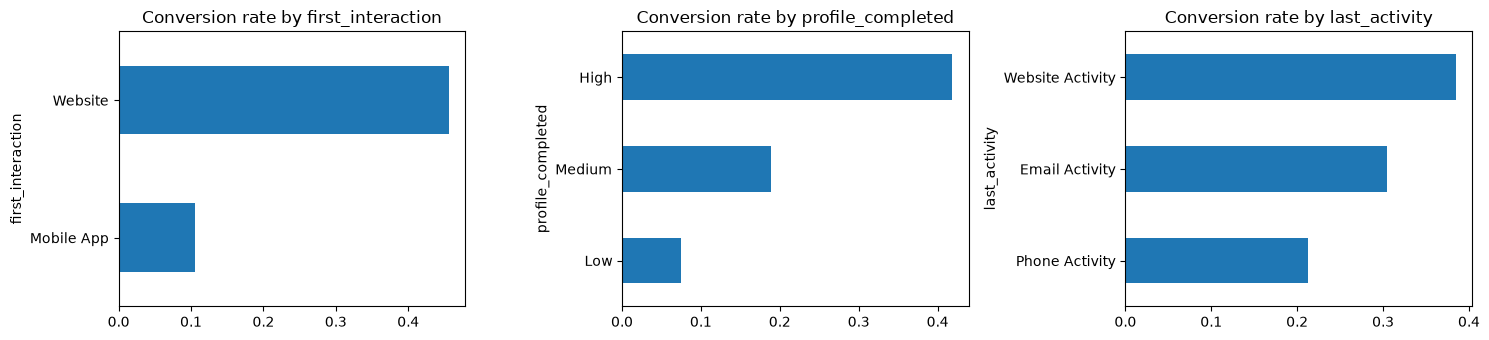

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
for a, col in zip(ax, ["first_interaction", "profile_completed", "last_activity"]):
    (pd.crosstab(df[col], df[TARGET], normalize="index")[1]
       .sort_values().plot(kind="barh", ax=a, title=f"Conversion rate by {col}"))
plt.tight_layout(); plt.show()

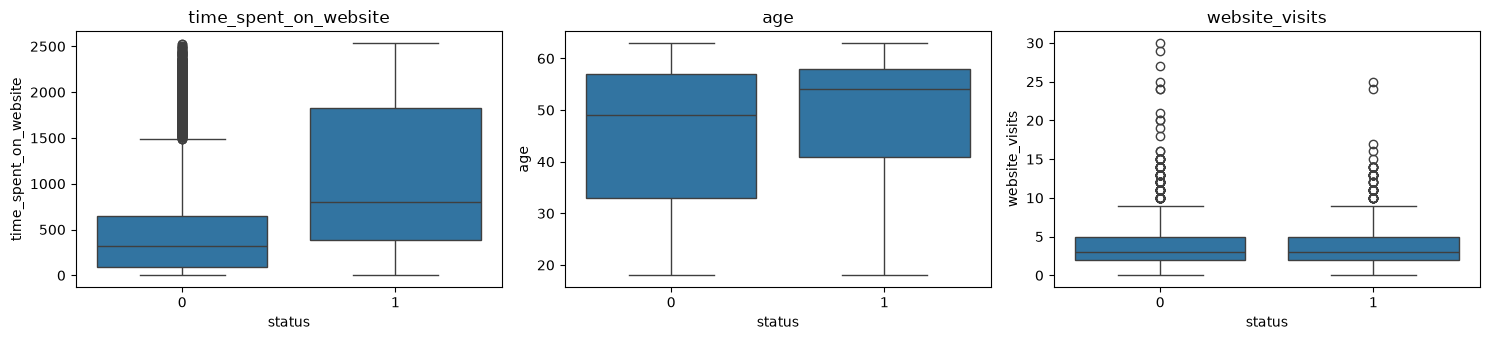

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
for a, col in zip(ax, ["time_spent_on_website", "age", "website_visits"]):
    sns.boxplot(data=df, x=TARGET, y=col, ax=a).set_title(col)
plt.tight_layout(); plt.show()

Strong signals before any model: **website as first interaction**, **high profile completion** and **more time on the website** all mean much higher conversion.

## 4. Encoding & stratified split
`stratify=y` keeps the same 30/70 ratio in train and test.

In [6]:
X = pd.get_dummies(df.drop(columns=TARGET), drop_first=True, dtype=int)
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
print(X_train.shape, X_test.shape)
print("positive rate train/test:", round(y_train.mean(), 3), round(y_test.mean(), 3))

(3218, 16) (1380, 16)
positive rate train/test: 0.299 0.299


## 5. Evaluation helper

In [7]:
def scores(model, X, y, threshold=0.5):
    proba = model.predict_proba(X)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {"accuracy": accuracy_score(y, pred), "precision": precision_score(y, pred),
            "recall": recall_score(y, pred), "f1": f1_score(y, pred), "roc_auc": roc_auc_score(y, proba)}

def report(model, name, threshold=0.5):
    """Train vs test metrics + test confusion matrix."""
    tr, te = scores(model, X_train, y_train, threshold), scores(model, X_test, y_test, threshold)
    display(pd.DataFrame({"train": tr, "test": te}).T.round(3))
    pred = (model.predict_proba(X_test)[:, 1] >= threshold).astype(int)
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Not converted", "Converted"],
                                            cmap="Blues", colorbar=False)
    plt.title(f"{name} — test"); plt.show()
    return te

results = {}

## 6. Logistic Regression
Linear model, outputs a **probability** (sigmoid). Scale the inputs so the regularization treats every feature fairly.

,accuracy,precision,recall,f1,roc_auc
train,0.800,0.626,0.822,0.711,0.869
test,0.795,0.615,0.840,0.710,0.881


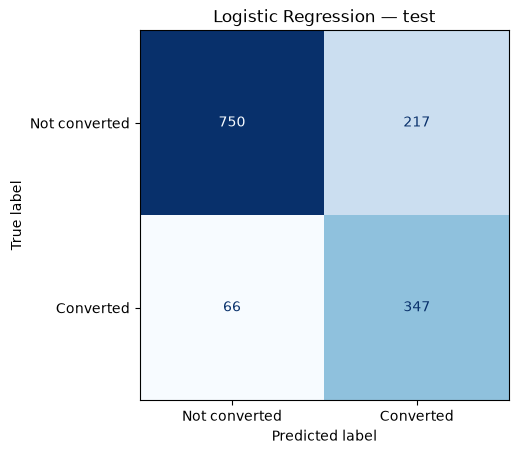

In [8]:
log_reg = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000))
log_reg.fit(X_train, y_train)
results["Logistic Regression"] = report(log_reg, "Logistic Regression")

**Odds ratios** = `exp(coefficient)`. On scaled data: 1 std up in the feature multiplies the odds of converting by this factor (> 1 helps, < 1 hurts).

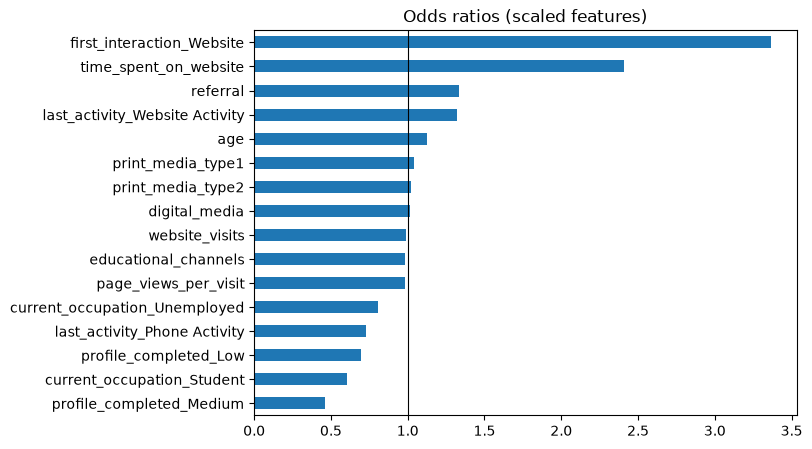

In [9]:
coefs = log_reg[-1].coef_[0]
odds = pd.Series(np.exp(coefs), index=X.columns).sort_values()
odds.plot(kind="barh", figsize=(7, 5), title="Odds ratios (scaled features)")
plt.axvline(1, color="k", lw=.8); plt.show()

### Threshold tuning
`predict()` uses 0.5. With the **precision-recall curve** we can pick the threshold that fits the business, e.g. *recall ≥ 0.90 with the best precision possible*.

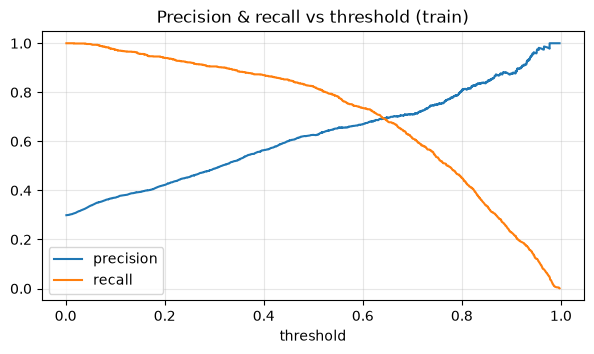

chosen threshold: 0.32


,accuracy,precision,recall,f1,roc_auc
train,0.708,0.506,0.90,0.648,0.869
test,0.706,0.505,0.92,0.652,0.881


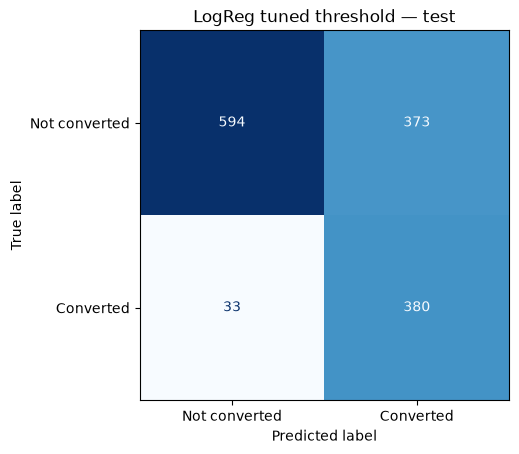

In [10]:
proba_train = log_reg.predict_proba(X_train)[:, 1]
prec, rec, thr = precision_recall_curve(y_train, proba_train)

plt.figure(figsize=(7, 3.5))
plt.plot(thr, prec[:-1], label="precision"); plt.plot(thr, rec[:-1], label="recall")
plt.xlabel("threshold"); plt.legend(); plt.grid(alpha=.3); plt.title("Precision & recall vs threshold (train)")
plt.show()

# Highest threshold that still keeps recall >= 0.90 (picked on TRAIN, evaluated on TEST)
best_thr = thr[rec[:-1] >= 0.90].max()
print(f"chosen threshold: {best_thr:.2f}")
results[f"Logistic Regression (thr={best_thr:.2f})"] = report(log_reg, "LogReg tuned threshold", best_thr)

## 7. KNN & SVM
Both use **distances**, so **scaling is mandatory**. KNN has no `class_weight`.

best k: {'kneighborsclassifier__n_neighbors': 5}


,accuracy,precision,recall,f1,roc_auc
train,0.864,0.813,0.707,0.756,0.929
test,0.820,0.729,0.632,0.677,0.837


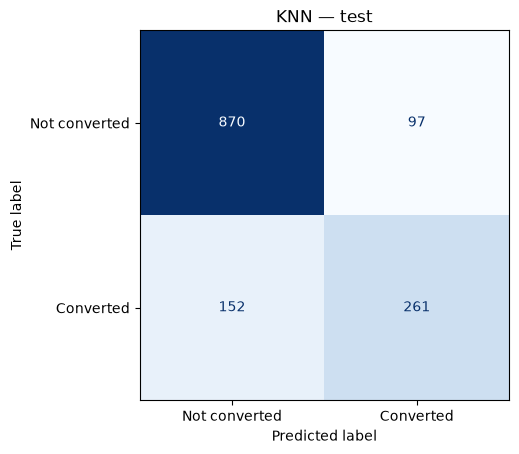

In [11]:
knn_grid = GridSearchCV(make_pipeline(StandardScaler(), KNeighborsClassifier()),
                        {"kneighborsclassifier__n_neighbors": [3, 5, 7, 11, 15, 21]},
                        scoring="recall", cv=5).fit(X_train, y_train)
print("best k:", knn_grid.best_params_)
results["KNN"] = report(knn_grid.best_estimator_, "KNN")

,accuracy,precision,recall,f1,roc_auc
train,0.866,0.774,0.778,0.776,0.923
test,0.833,0.716,0.734,0.725,0.892


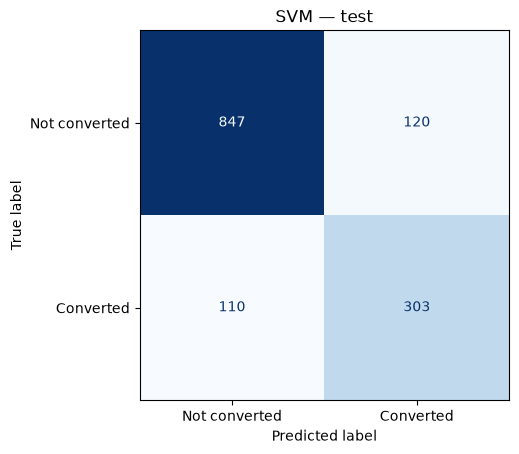

In [12]:
svm = make_pipeline(StandardScaler(), SVC(kernel="rbf", class_weight="balanced", probability=True, random_state=SEED))
svm.fit(X_train, y_train)
results["SVM (RBF)"] = report(svm, "SVM")

## 8. Decision Tree
Without limits it **memorizes** the training data.

,accuracy,precision,recall,f1,roc_auc
train,1.0,0.999,1.000,0.999,1.000
test,0.8,0.666,0.666,0.666,0.762


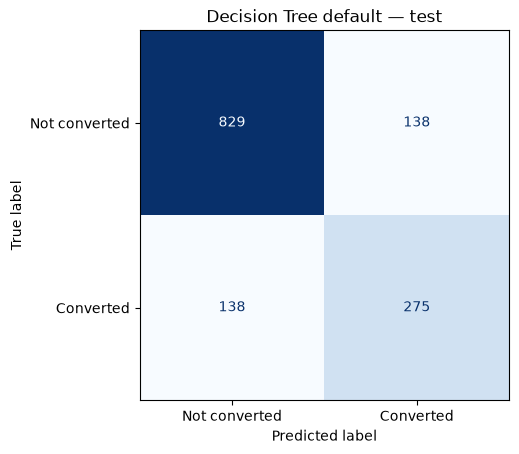

In [13]:
dt = DecisionTreeClassifier(class_weight="balanced", random_state=SEED).fit(X_train, y_train)
results["Decision Tree (default)"] = report(dt, "Decision Tree default")

Train recall = 1.0 but test recall is much lower: **overfitting**. **Pre-pruning** with GridSearchCV fixes it (optimizing recall).

best params: {'criterion': 'entropy', 'max_depth': 3, 'min_samples_leaf': 5}


,accuracy,precision,recall,f1,roc_auc
train,0.791,0.600,0.900,0.720,0.888
test,0.786,0.594,0.903,0.717,0.885


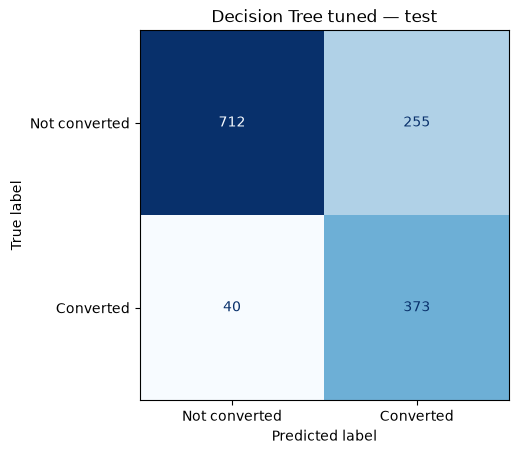

In [14]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
dt_grid = GridSearchCV(DecisionTreeClassifier(class_weight="balanced", random_state=SEED),
                       {"max_depth": [3, 4, 5, 6, 8], "min_samples_leaf": [5, 10, 20, 50],
                        "criterion": ["gini", "entropy"]},
                       scoring="recall", cv=cv).fit(X_train, y_train)
print("best params:", dt_grid.best_params_)
dt_tuned = dt_grid.best_estimator_
results["Decision Tree (tuned)"] = report(dt_tuned, "Decision Tree tuned")

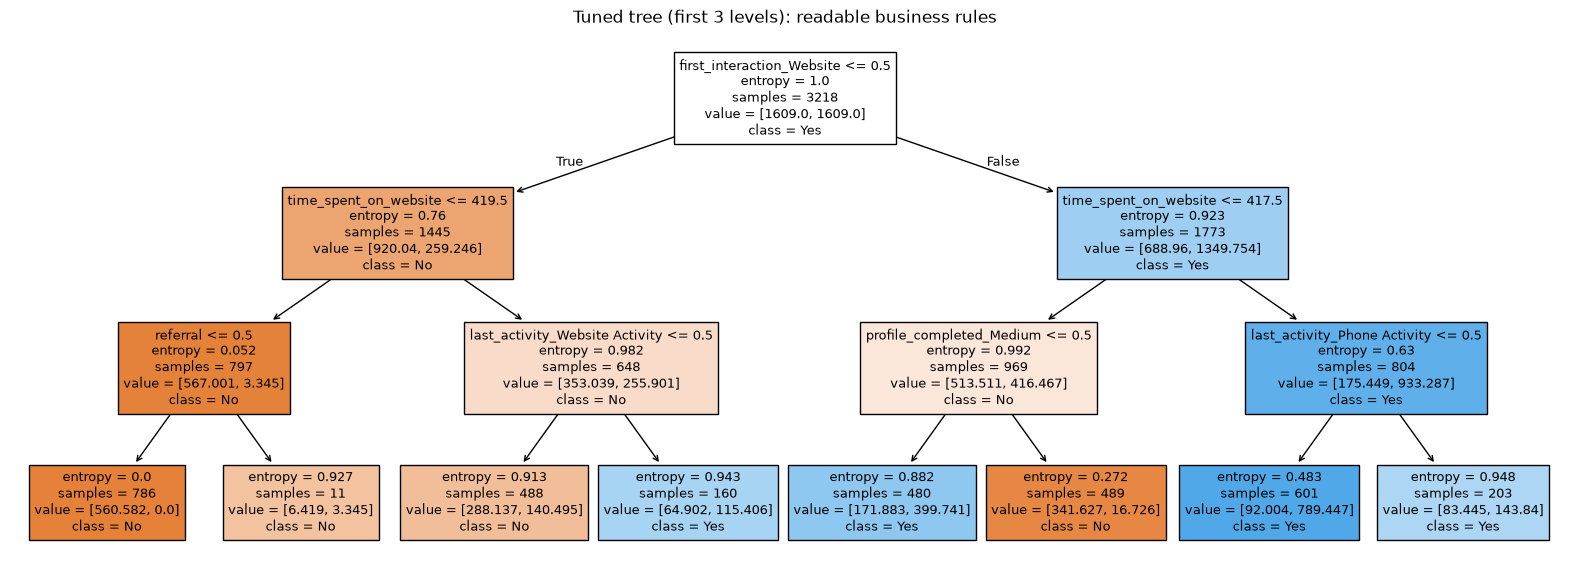

In [15]:
plt.figure(figsize=(20, 7))
plot_tree(dt_tuned, max_depth=3, feature_names=X.columns, class_names=["No", "Yes"], filled=True, fontsize=9)
plt.title("Tuned tree (first 3 levels): readable business rules"); plt.show()

## 9. Ensembles
- **Random Forest** (bagging): many deep trees on random samples + features, combined by vote.
- **AdaBoost / Gradient Boosting** (boosting): trees built one after another, each one focusing on the previous errors.

best params: {'max_depth': 6, 'max_features': 'sqrt', 'min_samples_leaf': 10, 'n_estimators': 200}


,accuracy,precision,recall,f1,roc_auc
train,0.846,0.689,0.888,0.776,0.939
test,0.832,0.667,0.877,0.757,0.928


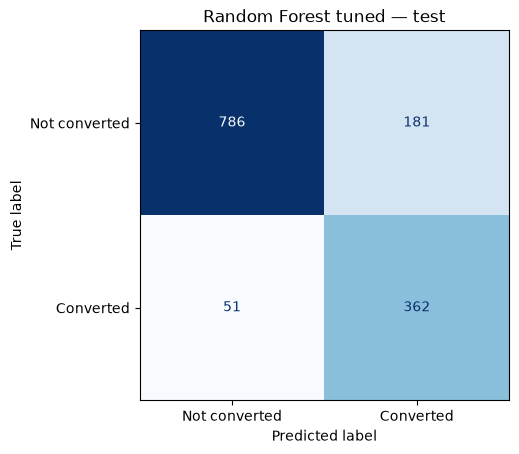

In [16]:
rf_grid = GridSearchCV(RandomForestClassifier(class_weight="balanced", random_state=SEED, n_jobs=-1),
                       {"n_estimators": [200], "max_depth": [6, 10, None], "min_samples_leaf": [1, 5, 10],
                        "max_features": ["sqrt", 0.5]},
                       scoring="recall", cv=cv).fit(X_train, y_train)
print("best params:", rf_grid.best_params_)
rf = rf_grid.best_estimator_
results["Random Forest (tuned)"] = report(rf, "Random Forest tuned")

,accuracy,precision,recall,f1,roc_auc
train,0.826,0.750,0.628,0.684,0.897
test,0.836,0.784,0.622,0.694,0.893


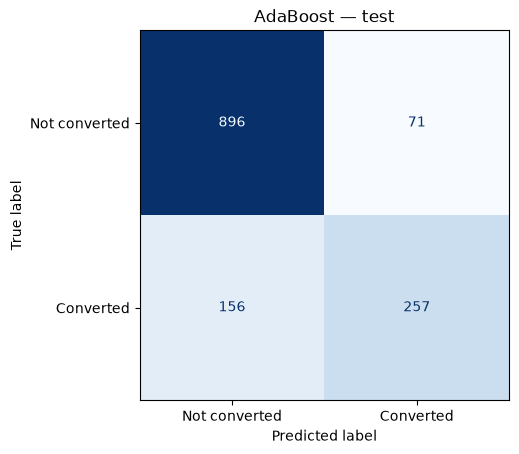

In [17]:
ada = AdaBoostClassifier(n_estimators=200, learning_rate=0.5, random_state=SEED).fit(X_train, y_train)
results["AdaBoost"] = report(ada, "AdaBoost")

,accuracy,precision,recall,f1,roc_auc
train,0.883,0.822,0.775,0.798,0.947
test,0.867,0.786,0.763,0.774,0.929


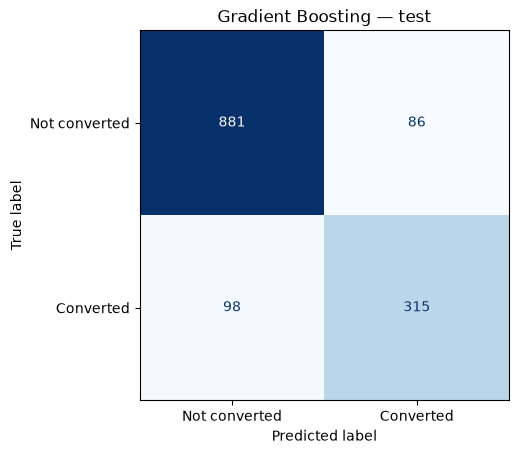

In [18]:
gb = GradientBoostingClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=SEED).fit(X_train, y_train)
results["Gradient Boosting"] = report(gb, "Gradient Boosting")

AdaBoost and Gradient Boosting have no `class_weight`, so with the 0.5 threshold their recall is lower. The fix is the same **threshold tuning** as in section 6 (or `sample_weight` in `fit`).

## 10. Model comparison (test set)

In [19]:
comparison = pd.DataFrame(results).T.round(3).sort_values("recall", ascending=False)
comparison.style.background_gradient(cmap="Greens", subset=["recall", "f1", "roc_auc"])

,accuracy,precision,recall,f1,roc_auc
Logistic Regression (thr=0.32),0.706000,0.505000,0.920000,0.652000,0.881000
Decision Tree (tuned),0.786000,0.594000,0.903000,0.717000,0.885000
Random Forest (tuned),0.832000,0.667000,0.877000,0.757000,0.928000
Logistic Regression,0.795000,0.615000,0.840000,0.710000,0.881000
Gradient Boosting,0.867000,0.786000,0.763000,0.774000,0.929000
SVM (RBF),0.833000,0.716000,0.734000,0.725000,0.892000
Decision Tree (default),0.800000,0.666000,0.666000,0.666000,0.762000
KNN,0.820000,0.729000,0.632000,0.677000,0.837000
AdaBoost,0.836000,0.784000,0.622000,0.694000,0.893000


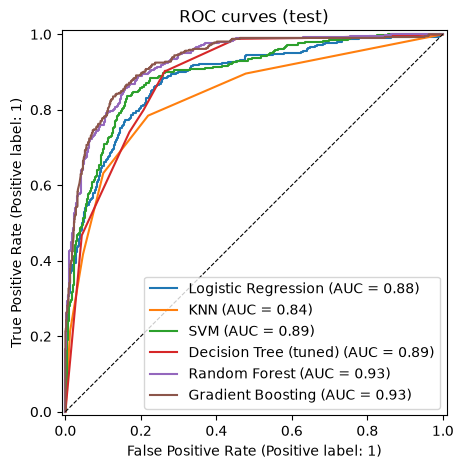

In [20]:
fig, ax = plt.subplots(figsize=(6, 5))
for name, m in {"Logistic Regression": log_reg, "KNN": knn_grid.best_estimator_, "SVM": svm,
                "Decision Tree (tuned)": dt_tuned, "Random Forest": rf, "Gradient Boosting": gb}.items():
    RocCurveDisplay.from_estimator(m, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", lw=.8)
ax.set_title("ROC curves (test)"); plt.show()

## 11. Feature importance & conclusion

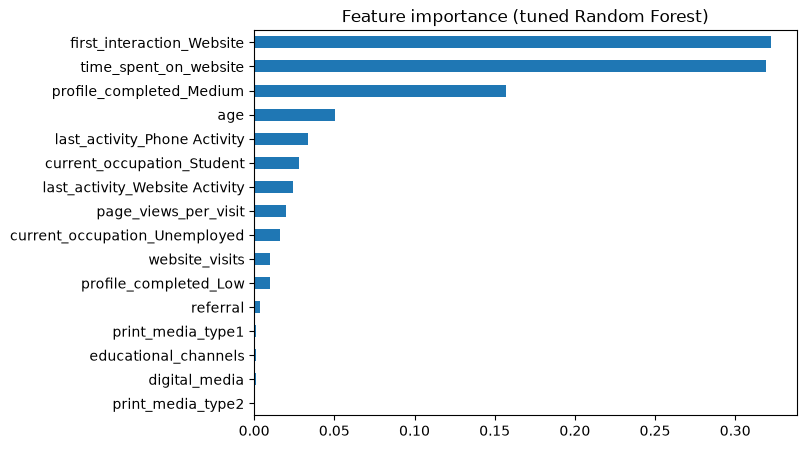

first_interaction_Website       0.322
time_spent_on_website           0.319
profile_completed_Medium        0.157
age                             0.051
last_activity_Phone Activity    0.034
dtype: float64

In [21]:
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
importance.plot(kind="barh", figsize=(7, 5), title="Feature importance (tuned Random Forest)")
plt.show()
importance.sort_values(ascending=False).head(5).round(3)

**Conclusions**
- **Accuracy is misleading** here: compare **recall** (business goal), **F1** (balance) and **ROC-AUC** (ranking quality).
- The default **Decision Tree overfits** (train recall 1.0 vs test 0.67). Pruning (depth 3) raises test recall to **0.90**, and its rules fit on one slide.
- **Recommended: tuned Random Forest** (test recall ≈ 0.88, F1 ≈ 0.76, ROC-AUC ≈ 0.93): high recall without losing too much precision.
- **Gradient Boosting** has the best F1 / AUC but lower recall at 0.5. Tuning the threshold, as done for Logistic Regression (0.5 to 0.32 raised recall to 0.92), would fix that.
- Top drivers: **first interaction = website** and **time spent on the website** (~32% each), then **profile completion**. The business should push leads to the website and to completing their profile.